# Food Delivery Data Quality, Cleaning, Transformation, and Business Analysis

### **Role:** Junior Data Analyst
### **Dataset:** `food_orders.csv`
### **Name :** Atluri Swetha

## Objective
Understand the dataset, profile data-quality issues, document cleaning rules, clean and transform the data, validate the results, answer business questions, create visualizations, and save the cleaned dataset.

**Working approach:** The original data is loaded into `df` and kept unchanged. All cleaning and derived columns are created in `work_df`, a copy of `df`. Missing financial values are not automatically replaced with zero.

## Task 1 - Load and understand the dataset

### Step 1 - Import required libraries

Pandas is used to load and analyze the dataset, NumPy supports numerical operations, and Matplotlib is used for charts.

In [52]:
# Import the libraries needed for analysis and visualizations.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)

### Step 2 - Load the dataset

Load `food_orders.csv` into `raw_df` and keep it unchanged. The `df` alias is retained so the remaining notebook cells continue to work.

In [53]:
# Load the original dataset and keep df as an alias for the existing notebook cells.
raw_df = pd.read_csv("food_orders.csv")
df = raw_df
print("Dataset loaded successfully.")
print("Rows and columns:", raw_df.shape)

Dataset loaded successfully.
Rows and columns: (1010, 14)


### Step 3 - Display the first five, last five, and a random sample of five rows

In [54]:
# Display the first five rows, last five rows, and five random rows.
print("First five rows:")
display(raw_df.head())

print("Last five rows:")
display(raw_df.tail())

print("Random sample of five rows:")
display(raw_df.sample(n=min(5, len(raw_df)), random_state=42))

First five rows:


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,NaN,146.0,27.0,0.0,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App


Last five rows:


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App
1006,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,1045.0,40.0,Cash on Delivery,10%,137.0,13.0,0.0,Sunny,Partner App
1007,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,1125.0,0.0,Credit Card,10%,95.0,16.0,50.0,Cloudy,Partner App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App


Random sample of five rows:


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
629,630,C1716,R2905,2024-01-13 04:16:47,2024-01-13 06:09:47,NaN,0.0,Cash on Delivery,5% on App,91.0,42.0,100.0,Rainy,Mobile App
788,789,C9659,R2778,2024-01-31 10:35:46,2024-01-31 12:07:46,714.0,40.0,Cash on Delivery,NaN,178.0,25.0,150.0,Rainy,Partner App
684,685,C7254,R2538,2024-01-07 23:31:43,2024-01-08 01:04:43,204.0,40.0,Digital Wallet,NaN,195.0,11.0,0.0,Cloudy,Mobile App
516,517,C8494,R2687,2024-01-23 05:41:17,2024-01-23 06:24:17,948.0,50.0,NaN,NaN,106.0,28.0,0.0,Sunny,Mobile App
529,530,C5268,R2697,2024-02-04 18:17:27,2024-02-04 18:51:27,1815.0,50.0,Cash on Delivery,15% New User,114.0,33.0,0.0,Sunny,Mobile App


### Step 4 - Display the number of rows and columns, column names, and data types

In [55]:
# Inspect the dataset's dimensions, column names, and current data types.
print("Number of rows:", raw_df.shape[0])
print("Number of columns:", raw_df.shape[1])
print("Column names:", raw_df.columns.tolist())
print("Data types:")
display(raw_df.dtypes.to_frame(name="Current Data Type"))

Number of rows: 1010
Number of columns: 14
Column names: ['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time', 'Delivery Date and Time', 'Order Value', 'Delivery Fee', 'Payment Method', 'Discounts and Offers', 'Commission Fee', 'Payment Processing Fee', 'Refunds/Chargebacks', 'Weather Condition', 'Order Channel']
Data types:


,Current Data Type
Order ID,int64
Customer ID,str
Restaurant ID,str
Order Date and Time,str
Delivery Date and Time,str
Order Value,float64
Delivery Fee,float64
Payment Method,str
Discounts and Offers,str
Commission Fee,float64


### Step 5 - Summarize numeric and categorical columns

In [56]:
# Summarize numeric columns and categorical columns separately.
print("Numeric column summary:")
display(raw_df.describe())

print("Categorical column summary:")
display(raw_df.describe(include="str"))

Numeric column summary:


,Order ID,Order Value,Delivery Fee,Commission Fee,Payment Processing Fee,Refunds/Chargebacks
count,1010.000000,969.000000,960.000000,970.000000,959.000000,970.000000
mean,499.221782,1055.901961,28.625000,127.042268,29.895725,27.886598
std,288.589479,529.534182,16.927281,43.013345,11.731583,49.383898
min,1.000000,104.000000,0.000000,50.000000,10.000000,0.000000
25%,248.250000,600.000000,20.000000,90.250000,20.000000,0.000000
50%,498.500000,1041.000000,30.000000,128.000000,30.000000,0.000000
75%,748.750000,1494.000000,40.000000,164.000000,40.000000,50.000000
max,1000.000000,1995.000000,50.000000,200.000000,50.000000,150.000000


Categorical column summary:


,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Payment Method,Discounts and Offers,Weather Condition,Order Channel
count,1010,1010,1010,1010,960,768,1010,1010
unique,947,621,1000,1000,3,4,4,3
top,C7949,R2317,2024-02-05 05:55:15,2024-02-05 07:33:15,Cash on Delivery,10%,Sunny,Mobile App
freq,3,6,2,2,341,221,405,693


### Step 6 - Describe each column and its expected data type

The expected type is based on the information a column represents. `Discounts and Offers` should be inspected because it may contain numeric amounts, offer labels, or both.

In [57]:
# Describe what each column represents and its expected business data type.
data_dictionary = pd.DataFrame({
    "Column": raw_df.columns,
    "Information": [
        "Unique order number", "Unique customer number", "Unique restaurant number",
        "Order date and time", "Delivery date and time", "Total order amount",
        "Delivery charge", "Payment method", "Discount or offer applied",
        "Commission earned by platform", "Payment processing cost",
        "Refund or chargeback amount", "Weather during the order",
        "Channel used to place the order"
    ],
    "Expected Data Type": [
        "Identifier", "Identifier", "Identifier", "Datetime", "Datetime",
        "Numeric", "Numeric", "Category", "Numeric/Category", "Numeric",
        "Numeric", "Numeric", "Category", "Category"
    ]
})
display(data_dictionary)

,Column,Information,Expected Data Type
0,Order ID,Unique order number,Identifier
1,Customer ID,Unique customer number,Identifier
2,Restaurant ID,Unique restaurant number,Identifier
3,Order Date and Time,Order date and time,Datetime
4,Delivery Date and Time,Delivery date and time,Datetime
5,Order Value,Total order amount,Numeric
6,Delivery Fee,Delivery charge,Numeric
7,Payment Method,Payment method,Category
8,Discounts and Offers,Discount or offer applied,Numeric/Category
9,Commission Fee,Commission earned by platform,Numeric


### Task 1 - Observation

One row represents a food-delivery order. `Order Value` is useful for analyzing order amounts; `Order Date and Time` and `Delivery Date and Time` help analyze delivery duration; `Payment Method` and `Payment Processing Fee` support payment analysis; and `Commission Fee`, `Delivery Fee`, `Payment Processing Fee`, and `Refunds/Chargebacks` are used for the assignment's simplified platform net revenue calculation.

## Task 2 - Profile data quality

The following cells inspect missing values, duplicates, identifiers, types, timestamps, delivery chronology, financial values, and category frequencies. These are diagnostic checks: they do not remove rows or replace missing values.

### Step 2.1 - How many missing values are present in each column

In [58]:
# Missing values in each column
print(df.isnull().sum())

Order ID                    0
Customer ID                 0
Restaurant ID               0
Order Date and Time         0
Delivery Date and Time      0
Order Value                41
Delivery Fee               50
Payment Method             50
Discounts and Offers      242
Commission Fee             40
Payment Processing Fee     51
Refunds/Chargebacks        40
Weather Condition           0
Order Channel               0
dtype: int64


### Step 2.2 What percentage of each column is missing

In [59]:
# Percentage of missing values in each column
print((df.isnull().mean() * 100).round(2))

Order ID                   0.00
Customer ID                0.00
Restaurant ID              0.00
Order Date and Time        0.00
Delivery Date and Time     0.00
Order Value                4.06
Delivery Fee               4.95
Payment Method             4.95
Discounts and Offers      23.96
Commission Fee             3.96
Payment Processing Fee     5.05
Refunds/Chargebacks        3.96
Weather Condition          0.00
Order Channel              0.00
dtype: float64


### Step 2.3 - How manu fully duplicated rows exist

In [60]:
# Count fully duplicated rows
print("Fully duplicated rows:", df.duplicated().sum())

Fully duplicated rows: 10


### Step 2.4 - Are there repeated Order ID values? Check before deciding what to remove

In [61]:
# Check repeated Order IDs
print(df["Order ID"].duplicated().sum())

# Display repeated Order IDs
display(df[df["Order ID"].duplicated(keep=False)].sort_values("Order ID"))

10


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App
1003,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App
1004,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App


### Step 2.5 - Which columns have unexpected data types?

In [62]:
# Check data types of all columns
print(df.dtypes)

Order ID                    int64
Customer ID                   str
Restaurant ID                 str
Order Date and Time           str
Delivery Date and Time        str
Order Value               float64
Delivery Fee              float64
Payment Method                str
Discounts and Offers          str
Commission Fee            float64
Payment Processing Fee    float64
Refunds/Chargebacks       float64
Weather Condition             str
Order Channel                 str
dtype: object


### Step 2.6 - Delivery before order

In [63]:
# Convert timestamp columns to datetime
df["Order Date and Time"] = pd.to_datetime(df["Order Date and Time"], errors="coerce")
df["Delivery Date and Time"] = pd.to_datetime(df["Delivery Date and Time"], errors="coerce")

# Check conversion results
print(df[["Order Date and Time", "Delivery Date and Time"]].dtypes)

Order Date and Time       datetime64[us]
Delivery Date and Time    datetime64[us]
dtype: object


### Step 2.7 - 7. Are there records where delivery occurs before the order?

In [64]:
# Find records where delivery occurs before the order
invalid = df[
    df["Order Date and Time"].notna() &
    df["Delivery Date and Time"].notna() &
    (df["Delivery Date and Time"] < df["Order Date and Time"])
]

print("Records where delivery occurs before order:", len(invalid))
display(invalid)

Records where delivery occurs before order: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel


### Step 2.8 - Are there negative or otherwise suspicious values in financial columns or calculated delivery duration?

In [65]:
# Check negative financial values
print((df[["Order Value", "Delivery Fee", "Commission Fee",
           "Payment Processing Fee", "Refunds/Chargebacks"]] < 0).sum())

# Check suspicious delivery duration
df["Delivery_Time_Minutes"] = (
    df["Delivery Date and Time"] - df["Order Date and Time"]
).dt.total_seconds() / 60

print(df[df["Delivery_Time_Minutes"] <= 0])

Order Value               0
Delivery Fee              0
Commission Fee            0
Payment Processing Fee    0
Refunds/Chargebacks       0
dtype: int64
Empty DataFrame
Columns: [Order ID, Customer ID, Restaurant ID, Order Date and Time, Delivery Date and Time, Order Value, Delivery Fee, Payment Method, Discounts and Offers, Commission Fee, Payment Processing Fee, Refunds/Chargebacks, Weather Condition, Order Channel, Delivery_Time_Minutes]
Index: []


### Step - 9. Check the distinct values and frequency counts for Payment Method, Discounts and Offers, Weather Condition, and Order Channel. 

In [66]:
# Check distinct values and frequency counts
cols = ["Payment Method", "Discounts and Offers",
        "Weather Condition", "Order Channel"]

for col in cols:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 Payment Method
Payment Method
Cash on Delivery    341
Credit Card         323
Digital Wallet      296
NaN                  50
Name: count, dtype: int64

 Discounts and Offers
Discounts and Offers
NaN             242
10%             221
50 off Promo    194
15% New User    183
5% on App       170
Name: count, dtype: int64

 Weather Condition
Weather Condition
Sunny     405
Cloudy    252
Rainy     202
Humid     151
Name: count, dtype: int64

 Order Channel
Order Channel
Mobile App     693
Partner App    165
Website        152
Name: count, dtype: int64


### Task 2 - Data-quality summary

The profiling cells above calculate the exact counts. Review the outputs and record the actual results in the final notebook. Important issues to assess include:

1. **Missing values:** Missing order values, fees, processing costs, and refunds can make financial totals incomplete. Missing values should not automatically be interpreted as zero.
2. **Exact duplicates and repeated Order IDs:** Exact duplicate rows can inflate order counts and financial totals. Repeated identifiers must be inspected before removal.
3. **Timestamp quality:** Unparseable timestamps or delivery-before-order records can make delivery-duration metrics unreliable.
4. **Financial values:** Negative or non-numeric amounts require investigation; a negative refund or chargeback may have a legitimate accounting meaning.
5. **Categorical consistency:** Unexpected or inconsistent labels can split counts across categories and mislead reporting.

## Task 3 - Design cleaning rules before changing data

The rules below are documented before the cleaning code. The approach preserves ambiguous records and avoids assuming missing financial values are zero.

| Data-quality issue | Chosen handling rule | Reason / business assumption |
|---|---|---|
| Exact duplicate rows | Inspect, then remove exact duplicates. | Exact duplicate rows may double-count an order or its financial values. |
| Repeated Order ID | Investigate repeated IDs; remove only confirmed duplicate transactions. Retain ambiguous cases. | Repeated IDs alone do not prove that the records are duplicates. |
| Missing Order Value | Retain row; exclude it from order-value metrics. | Missing order value is not the same as a zero-value order. |
| Missing Delivery Fee | Retain missing value and exclude from fee calculations. | Missing fee does not mean delivery was free. |
| Missing Commission Fee | Retain missing value and exclude from revenue calculations requiring it. | Missing commission is not necessarily zero revenue. |
| Missing Payment Processing Fee | Retain missing value and exclude from calculations requiring it. | Unknown processing cost should not be assumed to be zero. |
| Missing Refunds/Chargebacks | Retain missing value and exclude from calculations requiring it. | Missing refund information does not prove there was no refund. |
| Missing Payment Method | Fill missing or blank values with `Unknown`. | The label indicates that the method is not known. |
| Missing Discounts and Offers | Fill missing or blank values with `Not Specified`. | This does not claim that no offer was applied. |
| Invalid timestamps | Parse with `errors="coerce"` and count failures; retain rows. | Unparseable timestamps cannot support time calculations but other fields may be useful. |
| Missing timestamps | Retain rows; exclude them only from timestamp-dependent metrics. | Other valid information in the row may still be useful. |
| Delivery before order | Flag negative duration; exclude it from delivery-time statistics. | Negative duration is chronologically invalid, but the original record should be investigated. |
| Zero or very long duration | Flag zero and durations over 24 hours for review; do not automatically delete. | These may be edge cases or data errors. The 24-hour threshold is an exercise assumption. |
| Non-numeric financial values | Convert to numeric with explicit error handling and count invalid entries. | Invalid values should not silently become zero. |

## Task 4 - Clean the dataset

Create `work_df` as a copy of `raw_df`. Keep `raw_df` unchanged. Inspect exact duplicates before removing them, investigate repeated Order IDs without deleting them automatically, convert timestamps and financial columns, apply the documented category rules, and report rows removed and retained.

### Step 1 - Create a copy of the raw dataset

In [67]:
# Preserve the original dataset and perform cleaning on a separate copy.
raw_df = df.copy()
work_df = raw_df.copy()
initial_rows = len(work_df)

### Step 2 - Inspect and remove fully duplicated rows

In [68]:
# Count and display exact duplicate rows before removing them.
duplicates_removed = work_df.duplicated().sum()
print("Fully duplicated rows:", duplicates_removed)
display(work_df[work_df.duplicated(keep=False)])
work_df = work_df.drop_duplicates()

Fully duplicated rows: 10


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App,98.0
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App,88.0
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App,49.0
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App,53.0
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App,41.0
418,419,C2066,R2301,2024-01-27 18:49:41,2024-01-27 20:10:41,1857.0,30.0,Digital Wallet,NaN,106.0,43.0,0.0,Sunny,Partner App,81.0
496,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,1125.0,0.0,Credit Card,10%,95.0,16.0,50.0,Cloudy,Partner App,78.0
570,571,C7819,R2393,2024-01-18 21:30:36,2024-01-18 23:17:36,605.0,40.0,Cash on Delivery,50 off Promo,96.0,23.0,0.0,Sunny,Mobile App,107.0
579,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,1045.0,40.0,Cash on Delivery,10%,137.0,13.0,0.0,Sunny,Partner App,84.0
830,831,C4530,R2105,2024-01-18 05:44:53,2024-01-18 07:13:53,689.0,40.0,Credit Card,5% on App,159.0,39.0,0.0,Cloudy,Mobile App,89.0


### Step 3 - Check repeated Order ID values

In [69]:
# Inspect repeated Order IDs; do not remove them automatically.
print("Repeated Order IDs:", work_df["Order ID"].duplicated().sum())
display(work_df[work_df["Order ID"].duplicated(keep=False)].sort_values("Order ID"))

Repeated Order IDs: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes


### Step 4 - Convert timestamp columns to datetime

In [70]:
# Parse timestamps; invalid values become NaT for review.
for col in ["Order Date and Time", "Delivery Date and Time"]:
    work_df[col] = pd.to_datetime(work_df[col], errors="coerce")

### Step 5 - Convert financial columns to numeric

In [71]:
# Convert financial columns to numeric; unparseable values become missing.
financial_cols = ["Order Value", "Delivery Fee", "Commission Fee",
                  "Payment Processing Fee", "Refunds/Chargebacks"]

for col in financial_cols:
    work_df[col] = pd.to_numeric(work_df[col], errors="coerce")

### Step 6 - Apply the documented missing-category rules

In [72]:
# Fill missing category labels according to the documented cleaning rules.
for col, label in [("Payment Method", "Unknown"),
                  ("Discounts and Offers", "Not Specified")]:
    work_df[col] = work_df[col].astype("string").str.strip().replace("", pd.NA).fillna(label)

### Step 7 - Report rows removed and retained

In [73]:
# Compare row counts to document how many rows were removed or retained.
print("Rows before cleaning:", initial_rows)
print("Duplicate rows removed:", duplicates_removed)
print("Rows removed:", initial_rows - len(work_df))
print("Rows retained:", len(work_df))

Rows before cleaning: 1010
Duplicate rows removed: 10
Rows removed: 10
Rows retained: 1000


### Step 8 - Display the cleaned data and data types

In [74]:
# Preview the cleaned dataset and verify its column data types.
display(work_df.head())
print(work_df.dtypes)

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App,88.0
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App,35.0
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App,58.0
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,Not Specified,146.0,27.0,0.0,Rainy,Mobile App,46.0
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App,89.0


Order ID                           int64
Customer ID                          str
Restaurant ID                        str
Order Date and Time       datetime64[us]
Delivery Date and Time    datetime64[us]
Order Value                      float64
Delivery Fee                     float64
Payment Method                    string
Discounts and Offers              string
Commission Fee                   float64
Payment Processing Fee           float64
Refunds/Chargebacks              float64
Weather Condition                    str
Order Channel                        str
Delivery_Time_Minutes            float64
dtype: object


## Task 5 - Transform the Data and Create Derived Columns

Using `work_df`, create delivery duration, order date, order hour, and simplified platform net revenue. Revenue is calculated only when all four financial components are available.

### Step 1 - Calculate delivery time in minutes

In [75]:
# Calculate the time between ordering and delivery in minutes.
work_df["Delivery_Time_Minutes"] = (
    work_df["Delivery Date and Time"] -
    work_df["Order Date and Time"]
).dt.total_seconds() / 60

### Step 2 - Create order date and hour

In [76]:
# Extract the date and hour from the order timestamp.
work_df["Order_Date"] = work_df["Order Date and Time"].dt.date
work_df["Order_Hour"] = work_df["Order Date and Time"].dt.hour

### Step 3 - Calculate platform net revenue

In [77]:
# Calculate revenue only when all four financial components are present.
cols = ["Commission Fee", "Delivery Fee",
        "Payment Processing Fee", "Refunds/Chargebacks"]

work_df["Platform_Net_Revenue"] = (
    work_df["Commission Fee"] + work_df["Delivery Fee"]
    - work_df["Payment Processing Fee"] - work_df["Refunds/Chargebacks"]
).where(work_df[cols].notna().all(axis=1))

### Step 4 - Find records with missing delivery duration

In [78]:
# Show records where an order or delivery timestamp is missing or invalid.
display(work_df[work_df["Delivery_Time_Minutes"].isna()])

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue


A delivery duration cannot be calculated when either timestamp is missing or invalid.

### Step 5 - Flag negative or implausibly long durations

In [79]:
# Flag negative durations and durations longer than 180 minutes for review.
display(work_df[
    (work_df["Delivery_Time_Minutes"] < 0) |
    (work_df["Delivery_Time_Minutes"] > 180)
])

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue


Negative durations indicate a timestamp inconsistency. Durations over 180 minutes are flagged for investigation; this is an assignment review threshold, not a universal standard.

### Step 6 - Display the derived columns

In [80]:
# Preview the newly created columns.
display(work_df[[
    "Delivery_Time_Minutes", "Order_Date",
    "Order_Hour", "Platform_Net_Revenue"
]].head())

,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue
0,88.0,2024-02-01,1,103.0
1,35.0,2024-02-02,22,215.0
2,58.0,2024-01-31,5,180.0
3,46.0,2024-01-16,22,NaN
4,89.0,2024-01-29,1,NaN


### Task 5 — Answers

- **Records without delivery duration:** Rows with missing or invalid order or delivery timestamps.
- **Negative or implausible durations:** Review the rows flagged in Step 5. Negative values indicate timestamp inconsistencies; durations over 180 minutes need investigation.
- **Missing revenue components:** Missing does not mean zero. Replacing missing values with zero could misstate revenue, so `Platform_Net_Revenue` remains missing unless all four components are available.

`Platform_Net_Revenue` is a simplified analytical measure for this assignment, not a complete accounting definition.

## Task 6 — Answer the Business Questions

Use Pandas calculations on `work_df`. The results are calculated from the data, not hard-coded. For financial metrics, the code states which records are included and how missing values affect the results.

### Step 6.1 - Original and cleaned record counts

In [81]:
# Compare the number of records before and after cleaning.
print("Original records:", len(raw_df))
print("Cleaned records:", len(work_df))
print("Rows removed:", len(raw_df) - len(work_df))

Original records: 1010
Cleaned records: 1000
Rows removed: 10


### Step 6.2 - Valid Order Values and order-value summary

In [82]:
# Use only non-missing Order Value records for these calculations.
values = work_df["Order Value"].dropna()

print("Valid Order Values:", len(values))
print("Missing Order Values:", work_df["Order Value"].isna().sum())
print("Total Order Value:", values.sum())
print("Mean Order Value:", values.mean())
print("Median Order Value:", values.median())

Valid Order Values: 960
Missing Order Values: 40
Total Order Value: 1013415.0
Mean Order Value: 1055.640625
Median Order Value: 1040.0


**Interpretation:** The total, mean, and median use only records with a non-missing numeric `Order Value`. Missing order values are excluded, so the total may not represent all orders.

### Step 6.3 - Payment method with the most known orders

In [83]:
# Count known payment methods, excluding missing values and the label "Unknown".
known_payment = work_df.loc[
    work_df["Payment Method"].notna()
    & (work_df["Payment Method"] != "Unknown"),
    "Payment Method"
]
payment_counts = known_payment.value_counts()
display(payment_counts.head(1))

Payment Method
Cash on Delivery    336
Name: count, dtype: int64[pyarrow]

**Interpretation:** The most frequent result is the payment method with the largest number of orders among records with a known payment method.

### Step 6.4 - Order channel with the most orders

In [84]:
# Count orders for each channel and display the most common one.
channel_counts = work_df["Order Channel"].value_counts()
display(channel_counts.head(1))

Order Channel
Mobile App    686
Name: count, dtype: int64

**Interpretation:** The most frequent channel has the highest order count. Missing channel values are not included in the count.

### Step 6.5 - Most frequent weather condition

In [85]:
# Count recorded weather conditions and display the most frequent one.
weather_counts = work_df["Weather Condition"].value_counts()
display(weather_counts.head(1))

Weather Condition
Sunny    402
Name: count, dtype: int64

**Interpretation:** This shows the most frequently recorded weather condition. It does not show that weather caused changes in order volume.

### Step 6.6 - Mean and median valid delivery times

In [86]:
# Use available non-negative delivery durations for the summary.
times = work_df.loc[
    work_df["Delivery_Time_Minutes"].notna()
    & (work_df["Delivery_Time_Minutes"] >= 0),
    "Delivery_Time_Minutes"
]

print("Valid delivery durations:", len(times))
print("Mean delivery time:", times.mean())
print("Median delivery time:", times.median())

Valid delivery durations: 1000
Mean delivery time: 73.575
Median delivery time: 74.0


**Interpretation:** Missing and negative delivery durations are excluded. Investigate unusually long durations separately before deciding whether they are valid.

### Step 6.7 - Five restaurants with the highest order counts

In [87]:
# Count orders by restaurant and display the five highest counts.
restaurant_counts = work_df["Restaurant ID"].value_counts().head(5)
display(restaurant_counts)

Restaurant ID
R2317    6
R2804    5
R2726    5
R2016    5
R2523    5
Name: count, dtype: int64

**Interpretation:** These restaurants have the highest retained order counts. The ranking measures order volume, not revenue or customer satisfaction.

### Step 6.8 - Total Platform_Net_Revenue and included records

In [88]:
# Include only records where all four revenue components were available.
revenue = work_df["Platform_Net_Revenue"].dropna()

print("Records included:", len(revenue))
print("Total Platform_Net_Revenue:", revenue.sum())
print("Records excluded due to missing components:",
      work_df["Platform_Net_Revenue"].isna().sum())

Records included: 828
Total Platform_Net_Revenue: 80877.0
Records excluded due to missing components: 172


**Interpretation:** Only records with all four required financial components are included. Missing components are not treated as zero, so the total applies only to complete records and may not represent all orders. This is a simplified exercise metric, not a complete accounting definition.

## Task 7 - Create at least two visualizations

The following four charts summarize order volume, payment methods, delivery time, and daily order patterns. Each chart includes a title and axis labels, followed by a brief interpretation. The charts show counts and associations; they do not establish causation.

### Step 7.1 - Number of orders by Order Channel

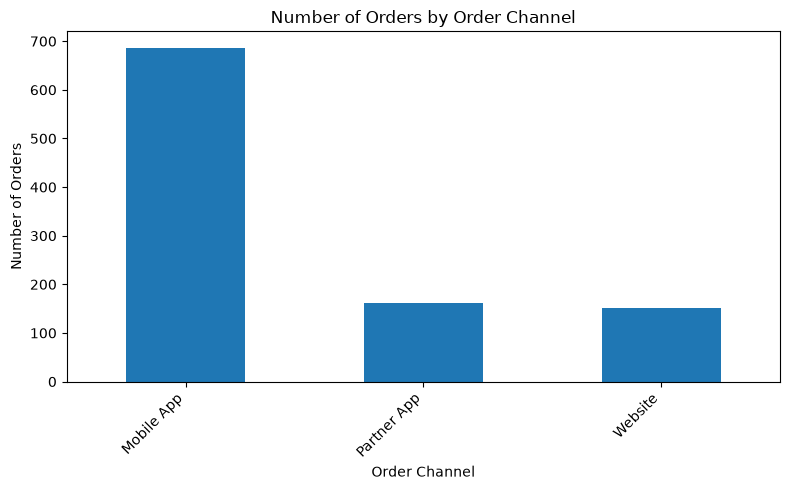

In [89]:
# Count orders in each channel.
work_df["Order Channel"].dropna().value_counts().plot(kind="bar", figsize=(8, 5))

plt.title("Number of Orders by Order Channel")
plt.xlabel("Order Channel")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observation:** The chart compares order counts across channels. The tallest bar represents the channel with the most orders; this does not necessarily mean it is the most profitable channel.

### Step 7.2 - Number of orders by Payment Method

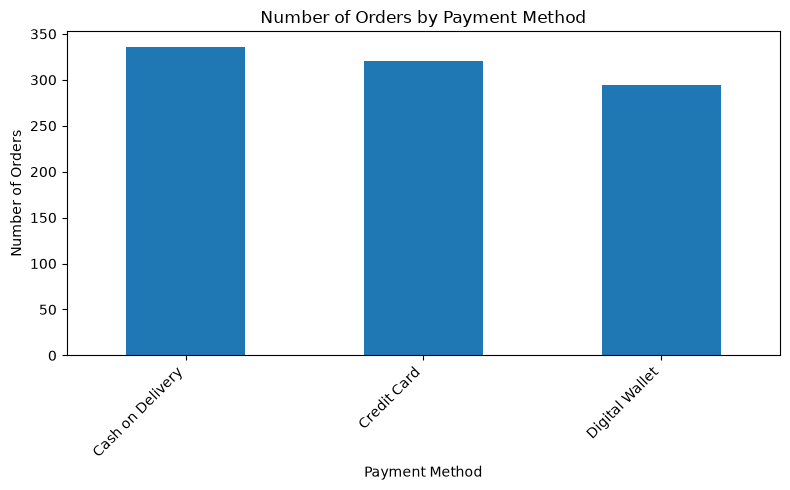

In [90]:
# Count orders for each known payment method.
payment_counts = work_df.loc[
    work_df["Payment Method"].notna()
    & (work_df["Payment Method"] != "Unknown"),
    "Payment Method"
].value_counts()

payment_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Number of Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observation:** The chart identifies the most frequently recorded payment methods. It shows payment patterns but does not explain why customers choose a particular method.

### Step 7.3 - Average delivery time by Weather Condition

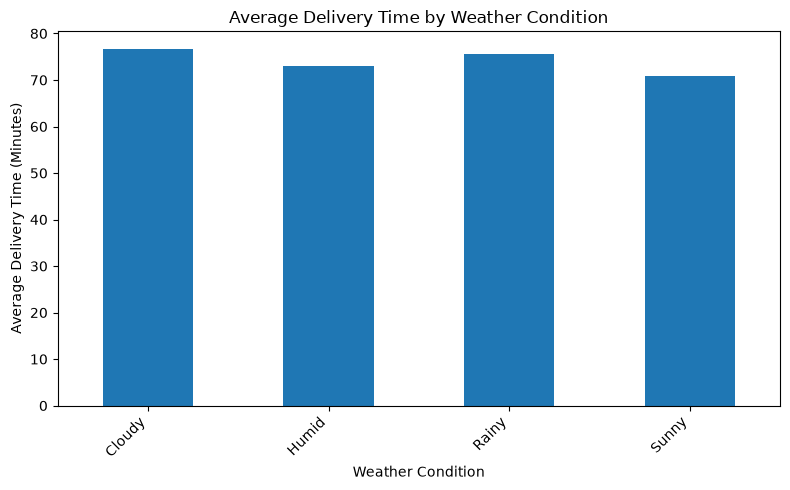

In [91]:
# Compare average delivery times using nonnegative durations.
valid_delivery = work_df.loc[
    work_df["Delivery_Time_Minutes"].notna()
    & (work_df["Delivery_Time_Minutes"] >= 0)
    & work_df["Weather Condition"].notna()
]

average_time_by_weather = valid_delivery.groupby(
    "Weather Condition"
)["Delivery_Time_Minutes"].mean()

average_time_by_weather.plot(kind="bar", figsize=(8, 5))
plt.title("Average Delivery Time by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Delivery Time (Minutes)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observation:** The chart compares average delivery times across recorded weather conditions. Differences show an association, but they do not prove that weather caused the differences; other factors may also affect delivery time.

### Step 7.4 - Daily order count using Order_Date

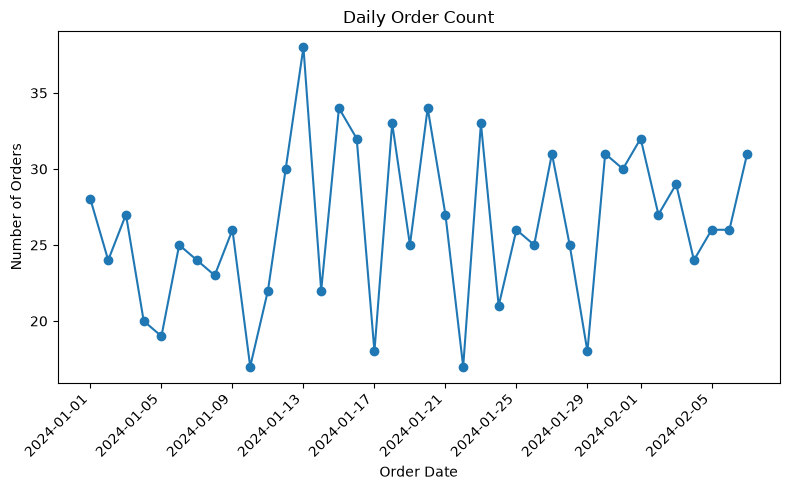

In [92]:
# Count orders recorded on each date.
daily_orders = work_df.groupby("Order_Date").size().sort_index()

daily_orders.plot(kind="line", marker="o", figsize=(8, 5))
plt.title("Daily Order Count")
plt.xlabel("Order Date")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Observation:** The chart shows how order volume changes from day to day. Peaks and dips identify dates with relatively higher or lower order counts, but the chart alone does not explain the reasons.

## Task 8 - Validate the Transformed Dataset

**Objective:** Validate the cleaned dataset, check the derived calculations, compare missing values, and report records removed or excluded. Remaining missing values are documented rather than automatically treated as errors.

### Step 8.1 - Check the expected columns

**Objective:** Confirm that all expected source columns are present in the cleaned dataset.

In [93]:
# List the expected source columns.
expected_columns = [
    "Order ID", "Customer ID", "Restaurant ID",
    "Order Date and Time", "Delivery Date and Time",
    "Order Value", "Delivery Fee", "Payment Method",
    "Discounts and Offers", "Commission Fee",
    "Payment Processing Fee", "Refunds/Chargebacks",
    "Weather Condition", "Order Channel"
]

# Display missing and unexpected columns.
print("Missing columns:", set(expected_columns) - set(work_df.columns))
print("Unexpected columns:", set(work_df.columns) - set(expected_columns))

Missing columns: set()
Unexpected columns: {'Delivery_Time_Minutes', 'Order_Hour', 'Order_Date', 'Platform_Net_Revenue'}


**Observation:** No missing expected columns means all required source columns are present. Additional columns may be derived columns created during analysis.

### Step 8.2 - Check data types

**Objective:** Confirm that date/time columns are datetime types and financial columns are numeric.

In [94]:
# Display the data types of all columns.
print(work_df.dtypes)

# Check datetime and financial columns.
datetime_columns = ["Order Date and Time", "Delivery Date and Time"]
financial_columns = [
    "Order Value", "Delivery Fee", "Commission Fee",
    "Payment Processing Fee", "Refunds/Chargebacks"
]

print("\nDatetime column types:")
print(work_df[datetime_columns].dtypes)

print("\nFinancial column types:")
print(work_df[financial_columns].dtypes)

Order ID                           int64
Customer ID                          str
Restaurant ID                        str
Order Date and Time       datetime64[us]
Delivery Date and Time    datetime64[us]
Order Value                      float64
Delivery Fee                     float64
Payment Method                    string
Discounts and Offers              string
Commission Fee                   float64
Payment Processing Fee           float64
Refunds/Chargebacks              float64
Weather Condition                    str
Order Channel                        str
Delivery_Time_Minutes            float64
Order_Date                        object
Order_Hour                         int32
Platform_Net_Revenue             float64
dtype: object

Datetime column types:
Order Date and Time       datetime64[us]
Delivery Date and Time    datetime64[us]
dtype: object

Financial column types:
Order Value               float64
Delivery Fee              float64
Commission Fee            float64
P

**Observation:** The date/time columns should have datetime types, and the financial columns should have numeric types. `Discounts and Offers` is checked separately because it may contain offer labels.

### Step 8.3 - Check fully duplicated rows

**Objective:** Verify that exact duplicate rows were removed during cleaning.

In [95]:
# Count exact duplicate rows remaining.
print("Duplicate rows remaining:", work_df.duplicated().sum())

Duplicate rows remaining: 0


**Observation:** The count should be zero if exact duplicate rows were removed. Repeated Order IDs are checked separately and are not automatically deleted.

### Step 8.4 - Check repeated Order IDs

**Objective:** Identify repeated Order IDs without automatically deleting those records.

In [96]:
# Find all records with a repeated Order ID.
repeated_orders = work_df[
    work_df["Order ID"].duplicated(keep=False)
].sort_values("Order ID")

print("Records with repeated Order IDs:", len(repeated_orders))
display(repeated_orders)

Records with repeated Order IDs: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue


**Observation:** Repeated Order IDs should be investigated. Repetition alone does not prove that a record is incorrect, so these records are retained unless further evidence supports removal.

### Step 8.5 - Validate delivery durations

**Objective:** Check for negative delivery durations and flag unusually long durations for review.

In [97]:
# Find negative delivery durations.
negative_times = work_df[work_df["Delivery_Time_Minutes"] < 0]

# Keep non-missing, non-negative durations for valid calculations.
valid_times = work_df[
    work_df["Delivery_Time_Minutes"].notna()
    & (work_df["Delivery_Time_Minutes"] >= 0)
]

# Flag durations over 180 minutes for review.
long_times = valid_times[valid_times["Delivery_Time_Minutes"] > 180]

print("Negative durations:", len(negative_times))
print("Valid non-negative durations:", len(valid_times))
print("Durations over 180 minutes flagged for review:", len(long_times))

display(negative_times)
display(long_times)

Negative durations: 0
Valid non-negative durations: 1000
Durations over 180 minutes flagged for review: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue


**Observation:** Negative durations are excluded from valid delivery-time calculations. Durations over 180 minutes are flagged for review; this threshold does not automatically mean they are errors.

### Step 8.6 - Verify delivery-time calculations

**Objective:** Recalculate delivery time for a few records and compare the results.

In [98]:
# Select five records with both timestamps available.
check = work_df.dropna(
    subset=["Order Date and Time", "Delivery Date and Time"]
).head(5).copy()

# Recalculate delivery time in minutes.
check["Recalculated_Time"] = (
    check["Delivery Date and Time"] - check["Order Date and Time"]
).dt.total_seconds() / 60

# Compare the stored and recalculated values.
check["Calculation_Correct"] = np.isclose(
    check["Delivery_Time_Minutes"],
    check["Recalculated_Time"],
    equal_nan=True
)

display(check[[
    "Order Date and Time", "Delivery Date and Time",
    "Delivery_Time_Minutes", "Recalculated_Time", "Calculation_Correct"
]])

,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes,Recalculated_Time,Calculation_Correct
0,2024-02-01 01:11:52,2024-02-01 02:39:52,88.0,88.0,True
1,2024-02-02 22:11:04,2024-02-02 22:46:04,35.0,35.0,True
2,2024-01-31 05:54:35,2024-01-31 06:52:35,58.0,58.0,True
3,2024-01-16 22:52:49,2024-01-16 23:38:49,46.0,46.0,True
4,2024-01-29 01:19:30,2024-01-29 02:48:30,89.0,89.0,True


**Observation:** The stored and recalculated durations should match for the inspected records. The comparison column indicates whether each checked calculation is correct.

### Step 8.7 - Verify the platform net revenue formula

**Objective:** Recalculate revenue for a few records where all four financial components are available.

In [99]:
# Select records with all required revenue components.
revenue_columns = [
    "Commission Fee", "Delivery Fee",
    "Payment Processing Fee", "Refunds/Chargebacks"
]
check = work_df.dropna(subset=revenue_columns).head(5).copy()

# Recalculate platform net revenue.
check["Recalculated_Revenue"] = (
    check["Commission Fee"] + check["Delivery Fee"]
    - check["Payment Processing Fee"] - check["Refunds/Chargebacks"]
)

# Compare the stored and recalculated values.
check["Formula_Correct"] = np.isclose(
    check["Platform_Net_Revenue"],
    check["Recalculated_Revenue"]
)

display(check[
    revenue_columns + [
        "Platform_Net_Revenue", "Recalculated_Revenue", "Formula_Correct"
    ]
])

,Commission Fee,Delivery Fee,Payment Processing Fee,Refunds/Chargebacks,Platform_Net_Revenue,Recalculated_Revenue,Formula_Correct
0,150.0,0.0,47.0,0.0,103.0,103.0,True
1,198.0,40.0,23.0,0.0,215.0,215.0,True
2,195.0,30.0,45.0,0.0,180.0,180.0,True
5,92.0,20.0,27.0,150.0,-65.0,-65.0,True
6,144.0,30.0,12.0,50.0,112.0,112.0,True


**Observation:** The stored and recalculated revenue values should match. Records missing any required component are excluded rather than treating missing values as zero.

### Step 8.8 - Compare missing values before and after cleaning

**Objective:** Compare missing-value counts in the original and cleaned datasets.

In [100]:
# Compare missing-value counts before and after cleaning.
missing_comparison = pd.DataFrame({
    "Before Cleaning": raw_df.isnull().sum(),
    "After Cleaning": work_df.isnull().sum()
})

display(missing_comparison)

,Before Cleaning,After Cleaning
Commission Fee,40.0,40
Customer ID,0.0,0
Delivery Date and Time,0.0,0
Delivery Fee,50.0,50
Delivery_Time_Minutes,0.0,0
Discounts and Offers,242.0,0
Order Channel,0.0,0
Order Date and Time,0.0,0
Order ID,0.0,0
Order Value,41.0,40


**Observation:** Missing values do not need to be reduced to zero. Remaining missing values should be understood and handled consistently.

### Step 8.9 - Report records removed, retained, and excluded

**Objective:** Report row counts and the number of records excluded from delivery-time and revenue calculations.

In [101]:
# Report records before and after cleaning.
print("Original records:", len(raw_df))
print("Retained records:", len(work_df))
print("Records removed:", len(raw_df) - len(work_df))

# Count records excluded from delivery-time calculations.
excluded_delivery = (
    work_df["Delivery_Time_Minutes"].isna()
    | (work_df["Delivery_Time_Minutes"] < 0)
)
print("Excluded from delivery-time calculations:", excluded_delivery.sum())

# Count records excluded from revenue calculations.
excluded_revenue = work_df["Platform_Net_Revenue"].isna().sum()
print("Excluded from revenue calculations:", excluded_revenue)

Original records: 1010
Retained records: 1000
Records removed: 10
Excluded from delivery-time calculations: 0
Excluded from revenue calculations: 172


**Observation:** Removed records were deleted during cleaning, while excluded records remain in the dataset but are not used in a calculation because required values are missing or invalid. The exclusion counts may overlap.

### Task 8 - Final validation summary

The dataset is validated by checking its columns and data types, duplicate rows, repeated Order IDs, delivery durations, derived calculations, missing values, and record counts. Any remaining missing values or flagged records are documented and handled consistently. Use the outputs above to report the actual validation results; do not mark a check as passed unless the output confirms it.